#Data

## Data folder

In this step we retrieve the data from the folder where it is located

In [103]:
# Connect Google Colab to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

path = '/content/drive/MyDrive/ML_proj/Projeto/'

Mounted at /content/drive


## Libraries

Install and import the libraries

### Install

In [104]:
# Step 1 - Install pandas using the pip install command
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn

### Import

In [105]:
# Step 2 - Import relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Use the command '%matplotlib inline' after importing matplotlib to guarantee that the plots are on the notebook


#set seaborn as default style for visualizations
sns.set()

## File access

Read the excel file provided

In [106]:
world_citizens = pd.read_excel(path + 'Data/world_citizens.xlsx')

#as a good practice, we avoided working on the dataset imported and created a copy instead
wd_ct = world_citizens.copy()
wd_ct.head(5)

,avg_monthly_entertainment_expenses,avg_weekly_exercise_hours,citizen_id,city,country,date_of_birth,eco_consciousness_score,education_level,environmental_awareness_rating,financial_wellness_index,...,investment_portfolio_value,investments_risk_appetite,investments_risk_tolerance,last_year_charity_donations,marital_status,name,social_media_influence_score,stress_management_score,title,well_being_level
0,9.9865,3.8026,467,MaracanaÃº,,2024-12-07,0.0000,0.5278,0.9437,97.3847,...,8.9116,1.1841,4.0812,0.0000,,JordÃ£o,11.7428,2.9500,Mr.,3.0475
1,44.3201,0.0333,2673,Elche,Spain,2024-12-06,0.0066,6.4485,0.4343,194.9810,...,0.0000,0.4306,5.7586,0.0000,,Felipe,6.0283,4.5148,Mr.,5.5013
2,40.2061,0.0000,6442,Gisborne,New Zealand,2024-12-05,0.0628,4.5544,0.6499,68.7633,...,0.0000,7.3330,9.7596,0.0112,,Ethan,5.3109,4.8626,Mr.,5.5577
3,5.7959,0.4477,7083,Las Palmas de Gran Canaria,Spain,2024-11-07,0.0000,5.2951,0.4020,105.3660,...,14.1973,7.0943,5.3910,0.4964,,SebastiÃ¡n,2.3345,NaN,Mr.,8.0834
4,9.4268,0.0000,4435,Wichita,United States,2024-11-06,0.0095,11.0494,0.3365,51.5046,...,11.1886,2.2444,NaN,0.0000,,Cody,2.8810,2.8470,Mr.,3.8327


# Visuals and Analysis of the variables

In [107]:
wd_ct.shape

(8327, 22)

## Well being level

A score indicating each citizen overall well being.

In [136]:
wd_ct['well_being_level'].describe()

,well_being_level
count,8202.000000
mean,4.763412
std,1.923769
min,1.137600
25%,3.412525
50%,4.321400
75%,5.621575
max,12.000000


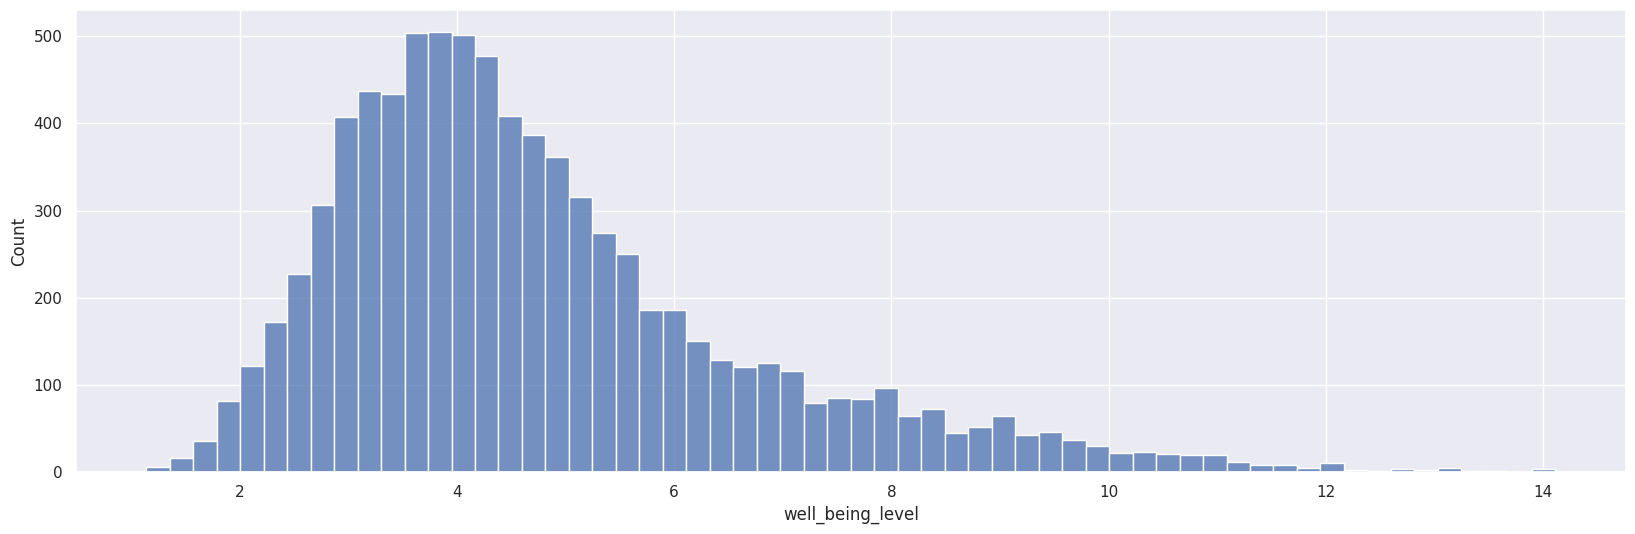

In [109]:
plt.figure(figsize=(20,6))
sns.histplot(wd_ct['well_being_level'])
plt.show()

<Axes: ylabel='well_being_level'>

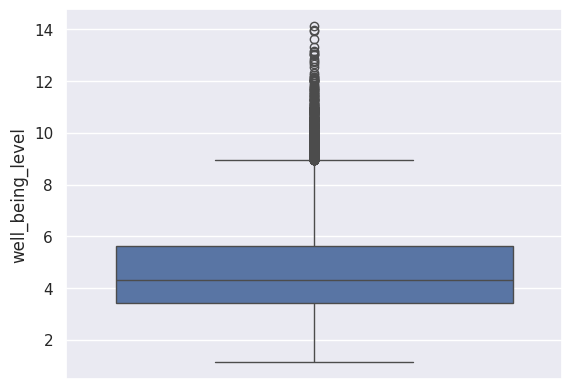

In [110]:
sns.boxplot(wd_ct['well_being_level'])

##Eco-score

A metric evaluating each person's consciousness and
actions towards ecological sustainability.

In [111]:
wd_ct['eco_consciousness_score'].describe()

,eco_consciousness_score
count,8119.000000
mean,0.131725
std,0.358699
min,-1.416700
25%,0.000000
50%,0.007800
75%,0.024450
max,3.247500


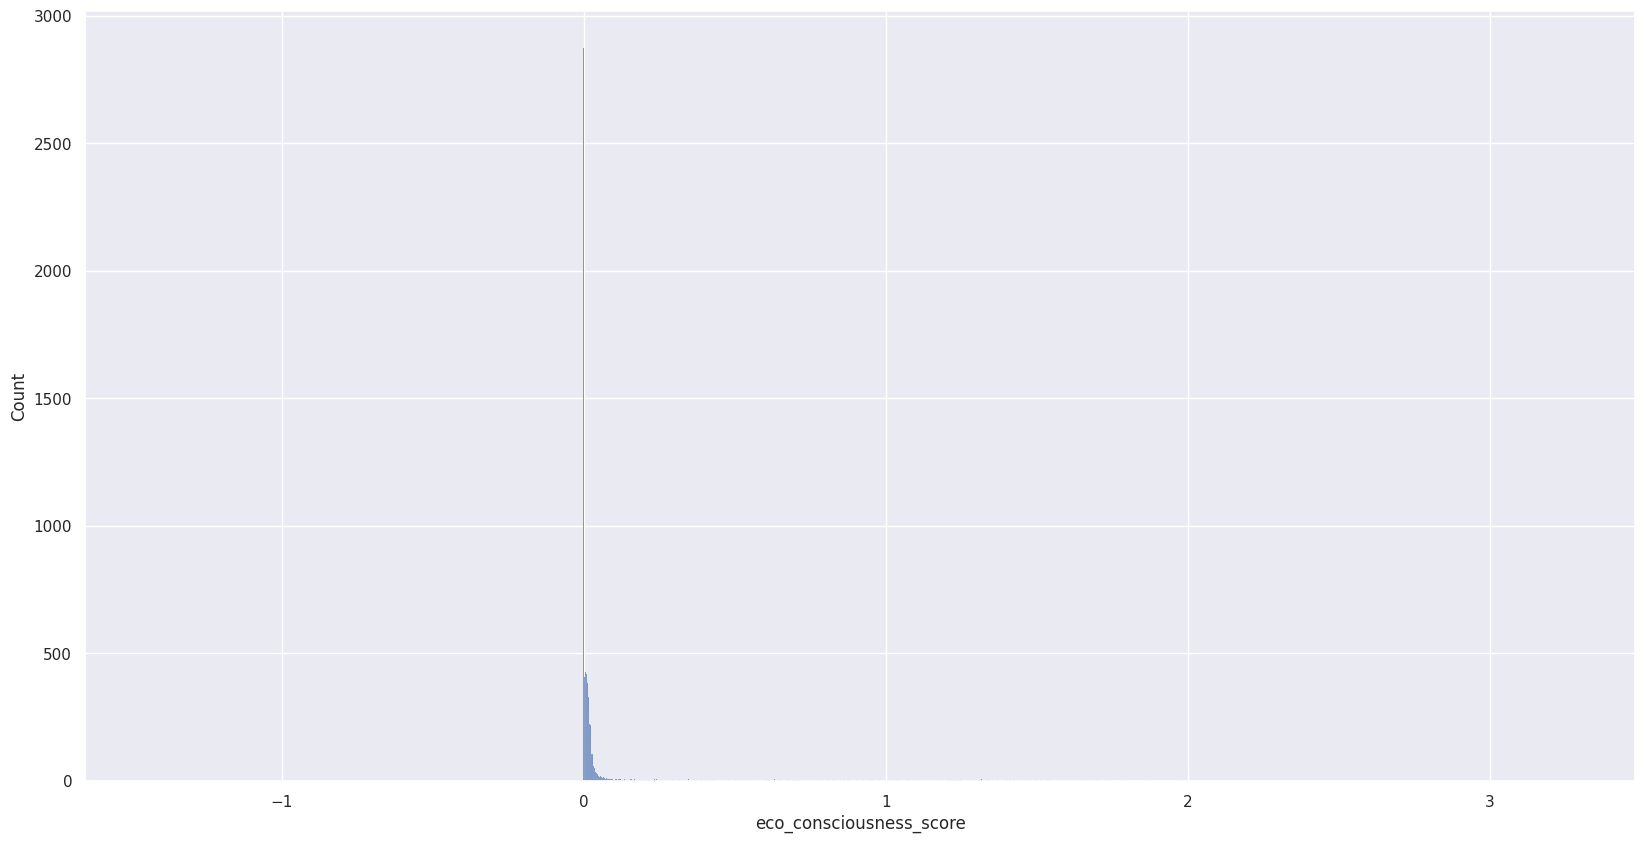

In [112]:
plt.figure(figsize=(20,10))
sns.histplot(wd_ct['eco_consciousness_score'])
plt.show()

<Axes: ylabel='eco_consciousness_score'>

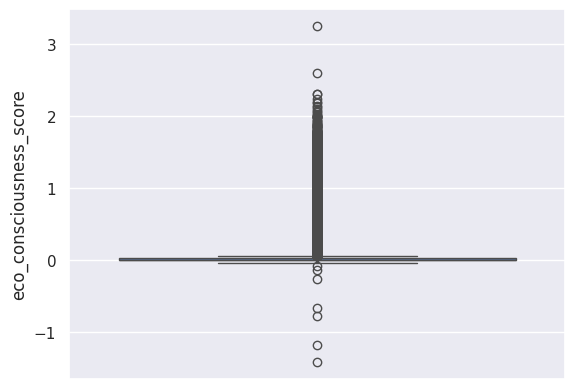

In [113]:
#plt.figure(figsize=(20,10))
sns.boxplot(wd_ct['eco_consciousness_score'])
#plt.show()

In [114]:
#number of outliers for this variable (0.024450 is the third quartile, and also the interquartile range since the first quartile is 0)

a = wd_ct[wd_ct['eco_consciousness_score'] >= 0.024450 + 1.5 * (0.024450)].shape[0]
print(f'Number of outliers: {a}')

Number of outliers: 1378


Due to this variable's complicated distribution, high amount of outliers and lack of interpretability of its scale, we decided to drop it.

In [115]:
wd_ct = wd_ct.drop(columns=['eco_consciousness_score'])

##Stress management

In [116]:
wd_ct['stress_management_score'].describe()

,stress_management_score
count,8034.000000
mean,3.318334
std,1.113446
min,0.319200
25%,2.560975
50%,3.150200
75%,3.980425
max,8.712300


In [117]:
print(f'Missing values: {wd_ct["stress_management_score"].isna().sum()}')

Missing values: 293


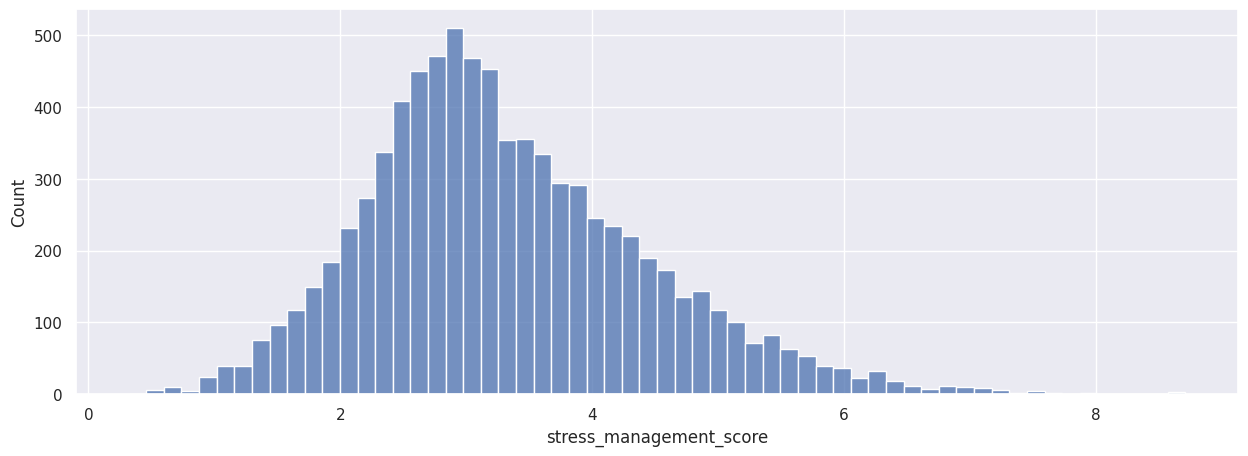

In [118]:
plt.figure(figsize=(15,5))
sns.histplot(wd_ct['stress_management_score'])
plt.show()

<Axes: ylabel='stress_management_score'>

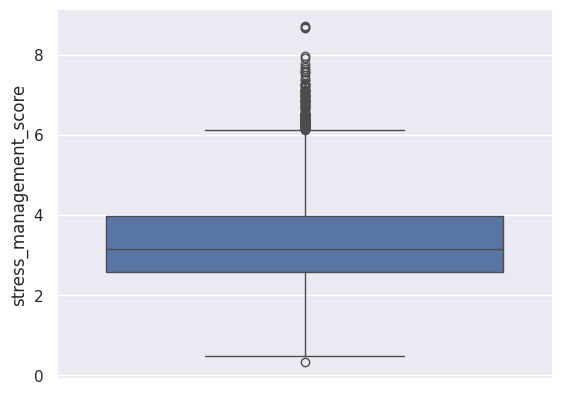

In [119]:
sns.boxplot(wd_ct['stress_management_score'])

In [135]:
#number of outliers for this variable


##Education Level

In [121]:
wd_ct['education_level'].describe()

Max: 14.244
Min: 0.0
Mean: 6.282893479342957
Median: 6.34465
Missing Values: 291


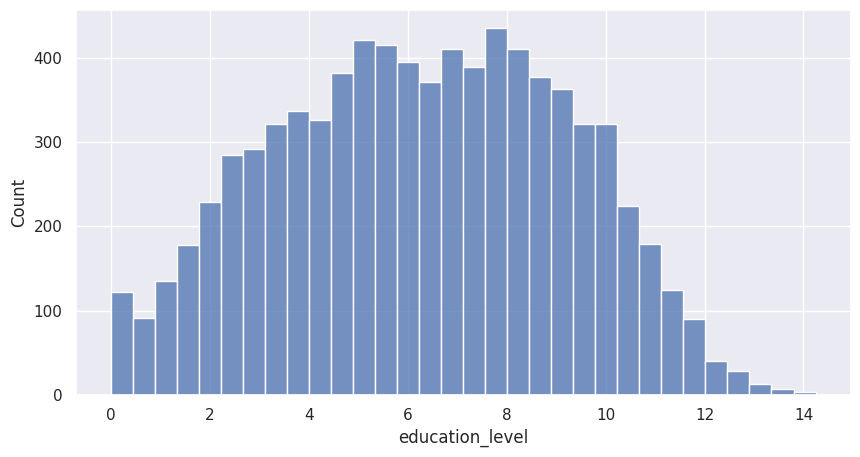

In [122]:
plt.figure(figsize=(10,5))
sns.histplot(wd_ct['education_level'])
plt.show()

<Axes: ylabel='education_level'>

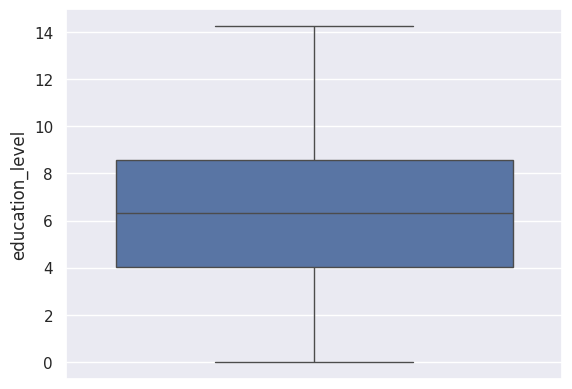

In [123]:
sns.boxplot(wd_ct['education_level'])

# Sugestions

##Well being

All values of the well being variable that are above 12 will round to 12

In [124]:
wd_ct['well_being_level'] = wd_ct['well_being_level'].apply(lambda x: 12 if x > 12 else x)

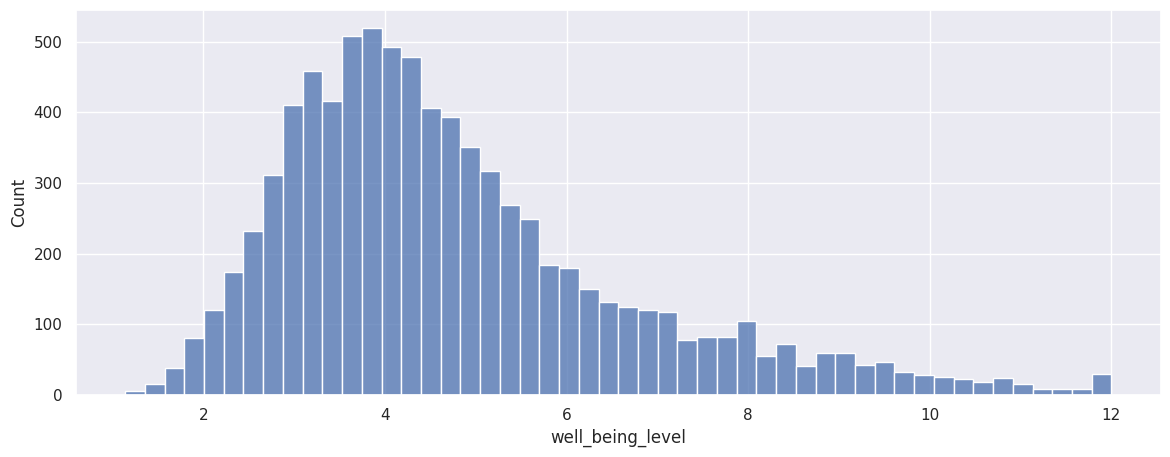

In [125]:
plt.figure(figsize=(14,5))
sns.histplot(wd_ct['well_being_level'])
plt.show()

<Axes: ylabel='well_being_level'>

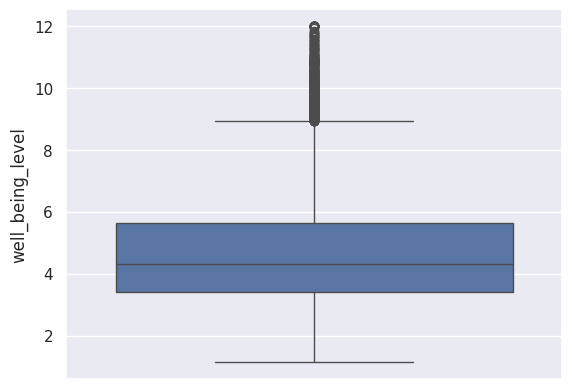

In [126]:
sns.boxplot(wd_ct['well_being_level'])

Drop all values that are above 10

In [127]:
wd_ct_t = wd_ct[wd_ct['well_being_level'] <= 10]

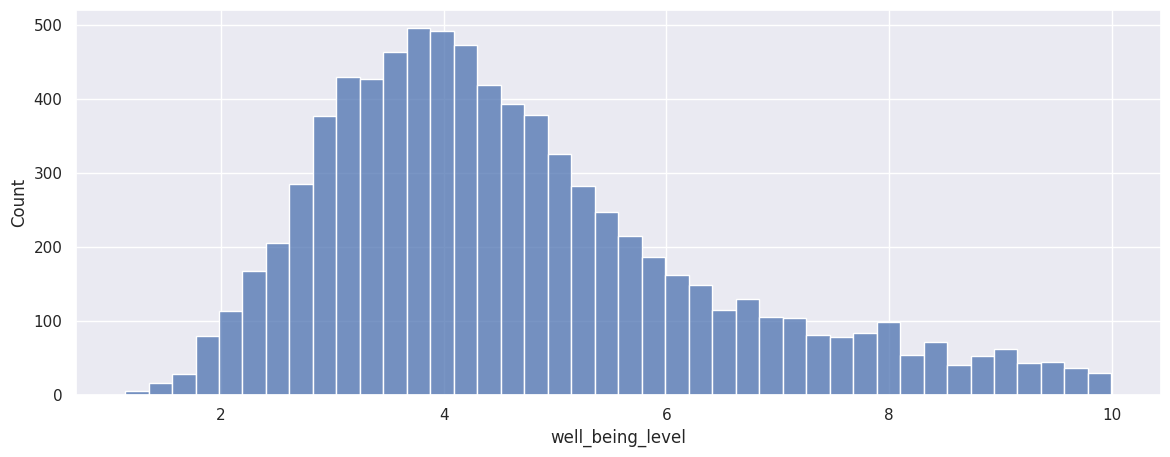

In [128]:
plt.figure(figsize=(14,5))
sns.histplot(wd_ct_t['well_being_level'])
plt.show()

<Axes: ylabel='well_being_level'>

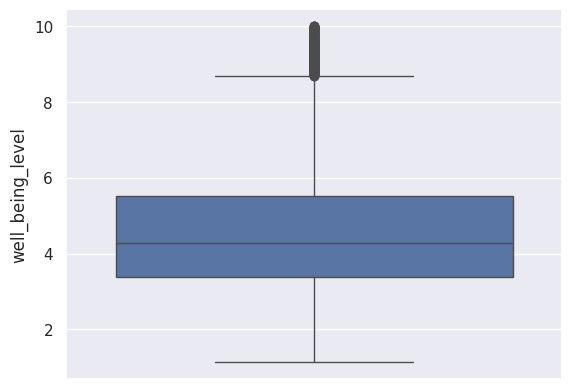

In [129]:
sns.boxplot(wd_ct_t['well_being_level'])

Calculate the percentage of rows removed

In [130]:
percentage = (wd_ct.shape[0] - wd_ct_t.shape[0]) *100 / wd_ct.shape[0]
print(f'Percentage of rows removed: {percentage}%')

Percentage of rows removed: 3.4706376846403266%


We decided to simply delete extreme values for this variable (bigger than 10). We still have some outliers, but now it is more manageable despite the slight loss of information.

## Eco-score

What does this variable mean? What is the scale? We have no information about this variable! It has barely none variance!

I say we drop it and burn the it to ashes like it never existed!

##Stress management

In [131]:
wd_ct['stress_management_score'] = wd_ct['stress_management_score'].rank(pct=True) * 100

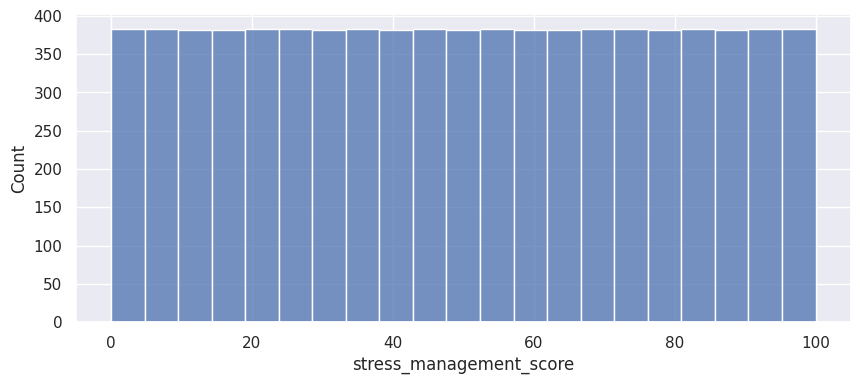

In [132]:
plt.figure(figsize=(10, 4))
sns.histplot(wd_ct['stress_management_score'])
plt.show()

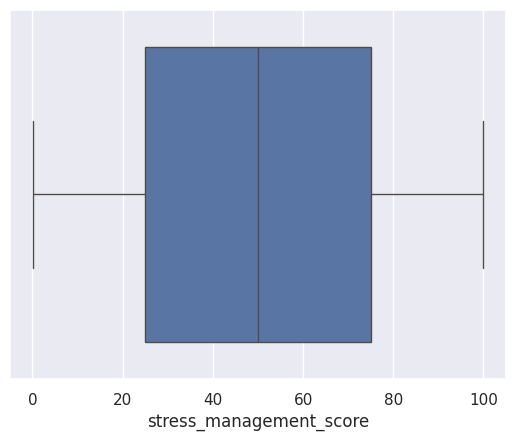

In [133]:
boxplot = sns.boxplot(x=wd_ct['stress_management_score'])